# BookFinder : moteur de recherche de livres (Version Locale CPU)

**Projet 7 - Domaine 2 : Recherche d'information et extraction**  
**Auteur :** BOUDERNA EL MAHDI

L'idée est de retrouver des livres à partir d'une description en langage naturel.
Je représente le corpus de deux manières (**TF-IDF** et **embeddings de phrases**),
puis je compare les résultats. Le notebook suit les 6 étapes du sujet :
1. Dataset
2. Prétraitement (`preprocessing.py` et statistiques)
3. Représentation (TF-IDF, Sentence Embeddings et matrice de similarité)
4. Modélisation (Index inversé, Voisins proches et similarité cosinus)
5. Évaluation (`Precision@10`, `Recall@10`, `MAP@10`)
6. Application (Fonction de recherche et interface Streamlit)

**Source des données :** Métadonnées publiques Goodreads (*UCSD Book Graph / Goodreads Young Adult*, Wan & McAuley).

## 0. Mise en route (Exécution locale sur CPU)

1. Placer le fichier `books.csv` (au moins 10 000 livres) dans le même dossier que ce notebook (ou dans `data/books.csv`).
2. Si un paquet manque dans votre environnement local, décommenter la ligne `%pip install` de la cellule suivante.
3. Exécuter le notebook du haut vers le bas (les résultats et les embeddings sont mis en cache dans `nlp_outputs/` pour éviter tout recalcul sur CPU).

Le fichier doit contenir les colonnes `book_id`, `title` et `description`.

In [63]:
# Si un paquet manque en local, décommente la ligne suivante :
%pip install pandas numpy scipy scikit-learn nltk sentence-transformers matplotlib joblib streamlit

Note: you may need to restart the kernel to use updated packages.


c:\Users\hp\Desktop\book-search-nlp\.venv\Scripts\python.exe: No module named pip


In [64]:
from pathlib import Path
import html
import re
import shutil
import textwrap

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer
from scipy.sparse import load_npz, save_npz
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sentence_transformers import SentenceTransformer

RANDOM_SEED = 42
REBUILD = False
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
DEVICE = "cpu"

np.random.seed(RANDOM_SEED)
pd.set_option("display.max_colwidth", 100)

print("Mode d'exécution : Local (", DEVICE.upper(), ")")

Mode d'exécution : Local ( CPU )


## 1. Dataset

Le corpus provient du jeu de données public **Goodreads Books Metadata** (sous-ensemble *Young Adult*, contenant les identifiants, titres et résumés des livres).
On nettoie les balises HTML, on supprime les doublons et les résumés trop courts (moins de 20 mots), et on conserve 10 000 livres.

In [65]:
data_candidates = [
    Path("books.csv"),
    Path("data/books.csv"),
    Path("../data/books.csv"),
]
DATA_PATH = next((p for p in data_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("books.csv introuvable, place-le dans le dossier du notebook.")

books = pd.read_csv(DATA_PATH, dtype={"book_id": "string"}).fillna("")
books = books[["book_id", "title", "description"]].copy()

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub("<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

books["title"] = books["title"].map(clean_text)
books["description"] = books["description"].map(clean_text)
books = books.drop_duplicates("book_id")
books = books[books["description"].str.split().str.len() >= 20]
books = books.head(10000).reset_index(drop=True)
books["search_text"] = books["title"] + ". " + books["description"]

OUTPUT_DIR = Path("nlp_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
books.to_csv(OUTPUT_DIR / "books_indexed.csv", index=False)

print("Dataset :", DATA_PATH)
print("Livres retenus :", len(books))
books.head(3)

Dataset : ..\data\books.csv
Livres retenus : 10000


,book_id,title,description,search_text
0,10099492,"Twelfth Grade Kills (The Chronicles of Vladimir Tod, #5)",It all comes down to this. Vlad's running out of time. The Elysian Council has given him weeks t...,"Twelfth Grade Kills (The Chronicles of Vladimir Tod, #5). It all comes down to this. Vlad's runn..."
1,22642971,The Body Electric,The future world is at peace. Ella Shepherd has dedicated her life to using her unique gift--the...,The Body Electric. The future world is at peace. Ella Shepherd has dedicated her life to using h...
2,25421507,The Ticket,Librarian Note: See Alternate Cover Edition . Tray Dunaway longs to be part of the popular set ...,The Ticket. Librarian Note: See Alternate Cover Edition . Tray Dunaway longs to be part of the ...


### 1.1 Statistiques descriptives du corpus

Quelques chiffres sur le corpus brut et sur la longueur des descriptions.

Nombre de livres : 10000
Titres distincts : 8018
Description moyenne (avant nettoyage) : 148.0 mots
Description médiane : 143 mots


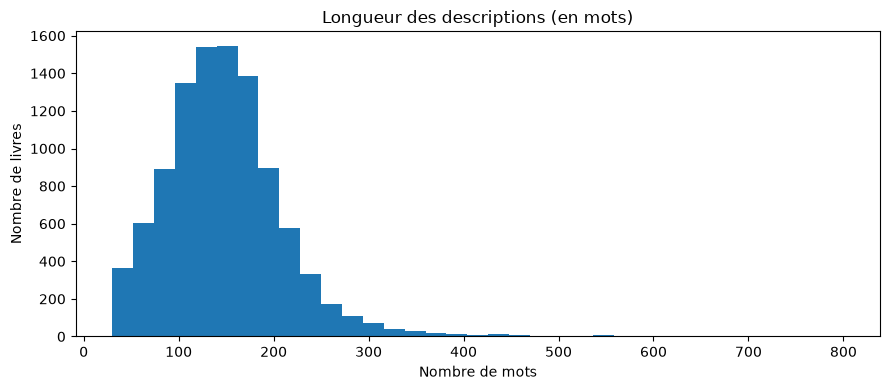

In [66]:
n_words = books["description"].str.split().str.len()

print("Nombre de livres :", len(books))
print("Titres distincts :", books["title"].nunique())
print("Description moyenne (avant nettoyage) :", round(n_words.mean(), 1), "mots")
print("Description médiane :", int(n_words.median()), "mots")

plt.figure(figsize=(9, 4))
plt.hist(n_words.clip(upper=800), bins=35)
plt.title("Longueur des descriptions (en mots)")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de livres")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_description_lengths.png", dpi=150)
plt.show()

## 2. Prétraitement

Pour **TF-IDF**, je passe le texte en minuscules, je supprime la ponctuation non informative, je retire les stopwords (en gardant les négations `no`, `not`, `never`) et j'applique un stemming de Porter.  
Pour les **embeddings**, je garde `search_text` presque brut car les modèles Transformer utilisent le contexte complet de la phrase.

On exporte également le script `nlp_outputs/preprocessing.py` demandé dans les livrables.

In [67]:
stemmer = PorterStemmer()
stopwords = set(ENGLISH_STOP_WORDS) - {"no", "not", "never"}

def preprocess(text):
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower())
    return " ".join(
        stemmer.stem(t) for t in tokens if t not in stopwords and len(t) > 1
    )

books["tokens"] = books["search_text"].map(preprocess)

# Export du livrable preprocessing.py
preprocessing_script = textwrap.dedent('''
    import html
    import re
    from nltk.stem import PorterStemmer
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

    stemmer = PorterStemmer()
    stopwords = set(ENGLISH_STOP_WORDS) - {"no", "not", "never"}

    def clean_text(text):
        text = html.unescape(str(text))
        text = re.sub("<[^>]+>", " ", text)
        return re.sub(r"\\s+", " ", text).strip()

    def preprocess(text):
        tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", clean_text(text).lower())
        return " ".join(
            stemmer.stem(t) for t in tokens if t not in stopwords and len(t) > 1
        )
''').strip() + "\n"

(OUTPUT_DIR / "preprocessing.py").write_text(preprocessing_script, encoding="utf-8")

# Statistiques sur les données nettoyées
clean_lengths = books["tokens"].str.split().str.len()
vocab_clean = set(" ".join(books["tokens"]).split())

exemple = "Young heroes are discovering magical powers, and they are not afraid!"
print("Avant :", exemple)
print("Après :", preprocess(exemple))
print("-" * 50)
print("Longueur moyenne après nettoyage :", round(clean_lengths.mean(), 1), "tokens")
print("Taille du vocabulaire nettoyé :", len(vocab_clean), "termes uniques")
print("Script sauvegardé :", OUTPUT_DIR / "preprocessing.py")

books[["title", "tokens"]].head(3)

Avant : Young heroes are discovering magical powers, and they are not afraid!
Après : young hero discov magic power not afraid
--------------------------------------------------
Longueur moyenne après nettoyage : 78.3 tokens
Taille du vocabulaire nettoyé : 32189 termes uniques
Script sauvegardé : nlp_outputs\preprocessing.py


,title,tokens
0,"Twelfth Grade Kills (The Chronicles of Vladimir Tod, #5)",twelfth grade kill chronicl vladimir tod come vlad' run time elysian council given week live tha...
1,The Body Electric,bodi electr futur world peac ella shepherd dedic life use uniqu gift abil enter people' dream me...
2,The Ticket,ticket librarian note altern cover edit tray dunaway long popular set school she' grow fast clot...


## 3. Représentation : TF-IDF

TF-IDF donne plus de poids aux mots qui caractérisent un livre et moins aux mots trop fréquents. J'ajoute aussi les bigrammes `(1, 2)`. Les vecteurs sont normalisés (norme L2), donc le produit scalaire correspond directement à la similarité cosinus.

In [68]:
tfidf_path = OUTPUT_DIR / "tfidf_vectorizer.joblib"
matrix_path = OUTPUT_DIR / "tfidf_matrix.npz"

if tfidf_path.exists() and matrix_path.exists() and not REBUILD:
    vectorizer = joblib.load(tfidf_path)
    tfidf_matrix = load_npz(matrix_path)
    print("TF-IDF chargé depuis le cache.")
else:
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
    tfidf_matrix = vectorizer.fit_transform(books["tokens"])
    joblib.dump(vectorizer, tfidf_path)
    save_npz(matrix_path, tfidf_matrix)
    print("TF-IDF calculé et sauvegardé.")

print("Matrice TF-IDF :", tfidf_matrix.shape)
print("Valeurs non nulles :", tfidf_matrix.nnz)

TF-IDF chargé depuis le cache.
Matrice TF-IDF : (10000, 136985)
Valeurs non nulles : 1072775


In [69]:
import joblib
import numpy as np
import pandas as pd
from scipy.sparse import load_npz
import re
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

vectorizer = joblib.load('nlp_outputs/tfidf_vectorizer.joblib')
tfidf_matrix = load_npz('nlp_outputs/tfidf_matrix.npz')
books = pd.read_csv('nlp_outputs/books_indexed.csv')

stemmer = PorterStemmer()
stopwords = set(ENGLISH_STOP_WORDS) - {'no', 'not', 'never'}

def preprocess(text):
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower())
    return " ".join(stemmer.stem(t) for t in tokens if t not in stopwords and len(t) > 1)

inverted_index = tfidf_matrix.tocsc()

def search_tfidf(query, k=5):
    q = vectorizer.transform([preprocess(query)])
    lists = [
        inverted_index.indices[inverted_index.indptr[t]:inverted_index.indptr[t + 1]]
        for t in q.indices
    ]
    candidates = np.unique(np.concatenate(lists))
    scores = (tfidf_matrix[candidates] @ q.T).toarray().ravel()
    order = np.argsort(-scores)[:k]
    return [(int(candidates[i]), float(scores[i])) for i in order if scores[i] > 0]

query = "a fantasy adventure with dragons and magic"
results = search_tfidf(query, 5)
doc_indices = [idx for idx, score in results]

query_terms = [t for t in preprocess(query).split() if t in vectorizer.vocabulary_]
term_indices = [vectorizer.vocabulary_[t] for t in query_terms]

submatrix = tfidf_matrix[doc_indices][:, term_indices].toarray()
df_weights = pd.DataFrame(
    submatrix,
    index=[f"Top {i+1}: {books['title'].iloc[idx][:35]}" for i, idx in enumerate(doc_indices)],
    columns=query_terms
)
df_weights["Score Total"] = [round(score, 4) for idx, score in results]
print(df_weights.to_string())



                                             fantasi  adventur    dragon     magic  Score Total
Top 1: Zachary Pill Dragon Magic: Book 1    0.000000  0.000000  0.106527  0.118180       0.1743
Top 2: The Bridge to Nowhere (Magemother,   0.121138  0.085381  0.000000  0.027798       0.1455
Top 3: The Prince Returns (The Keeper of D  0.000000  0.000000  0.165646  0.036843       0.1266
Top 4: The Prince Returns (The Keeper of D  0.000000  0.000000  0.165646  0.036843       0.1266
Top 5: Sevara: Dawn of Hope                 0.078457  0.119559  0.000000  0.000000       0.1260


### 3.0 Extrait de la matrice : Termes les plus discriminants (Top TF-IDF)

La matrice TF-IDF complète étant géante et creuse (~0,08 % de valeurs non nulles), on illustre son contenu en affichant les termes aux poids TF-IDF les plus élevés pour le premier livre du corpus.

In [70]:
# Option 1 : Affichage des valeurs non nulles les plus fortes pour un livre
feature_names = np.array(vectorizer.get_feature_names_out())
row_0 = tfidf_matrix[0].tocoo()

top_terms = pd.DataFrame({
    "Terme / N-gram": feature_names[row_0.col],
    "Poids TF-IDF": row_0.data
}).sort_values(by="Poids TF-IDF", ascending=False).head(10).reset_index(drop=True)

print(f"Livre exemple : '{books['title'].iloc[0]}'")
print(f"Nombre de termes non nuls pour ce livre : {len(row_0.data)}")
display(top_terms.round(4))


Livre exemple : 'Twelfth Grade Kills (The Chronicles of Vladimir Tod, #5)'
Nombre de termes non nuls pour ce livre : 79


,Terme / N-gram,Poids TF-IDF
0,vlad,0.2826
1,vladimir tod,0.2361
2,chronicl vladimir,0.2361
3,tod,0.2247
4,vladimir,0.1929
5,just care,0.1509
6,bathori,0.1509
7,societi doesn,0.1509
8,warm blood,0.1509
9,live that,0.1509


### 3.1 Modélisation TF-IDF : Index inversé et fonction de score cosinus

On construit un index inversé (matrice creuse par colonnes CSC) qui associe chaque terme à la liste des livres qui le contiennent, puis on classe uniquement les livres candidats par similarité cosinus.

In [71]:
# Index inversé : pour chaque terme, la liste des livres qui le contiennent.
inverted_index = tfidf_matrix.tocsc()

raw_term = "magic"
stemmed_term = preprocess(raw_term)
term_id = vectorizer.vocabulary_.get(stemmed_term)

if term_id is not None:
    start = inverted_index.indptr[term_id]
    end = inverted_index.indptr[term_id + 1]
    postings = inverted_index.indices[start:end]
    print(f"Le terme '{raw_term}' (racine : '{stemmed_term}') apparaît dans {len(postings)} livres.")
    livres_du_terme = books.iloc[postings[:5]][["title"]]
else:
    print(f"'{raw_term}' absent du vocabulaire.")
    livres_du_terme = None

livres_du_terme

Le terme 'magic' (racine : 'magic') apparaît dans 852 livres.


,title
17,Winter Falls: A Tale of the Snow Queen
38,"Cheating to Win (Sweet Valley High, #77)"
41,Tortall and Other Lands: A Collection of Tales
59,"King of Snowflakes (West Coast Boys, #1)"
68,The Romeo Catchers (The Casquette Girls #2)


In [72]:
def show_results(results, k=10):
    rows = []
    for rank, (idx, score) in enumerate(results[:k], start=1):
        b = books.iloc[int(idx)]
        rows.append({
            "rang": rank,
            "titre": b["title"],
            "score": round(float(score), 4),
            "extrait": b["description"][:200],
        })
    return pd.DataFrame(rows)

def search_tfidf(query, k=10):
    q = vectorizer.transform([preprocess(query)])
    if q.nnz == 0:
        return []
    # Récupération des documents candidats via l'index inversé
    lists = [
        inverted_index.indices[inverted_index.indptr[t]:inverted_index.indptr[t + 1]]
        for t in q.indices
    ]
    candidates = np.unique(np.concatenate(lists))
    # Fonction de score : similarité cosinus (produit scalaire sur vecteurs normalisés)
    scores = (tfidf_matrix[candidates] @ q.T).toarray().ravel()
    order = np.argsort(-scores)[:k]
    return [(int(candidates[i]), float(scores[i])) for i in order if scores[i] > 0]

query = "a fantasy adventure with dragons and magic"
print("Requête :", query)
show_results(search_tfidf(query), 5)

Requête : a fantasy adventure with dragons and magic


,rang,titre,score,extrait
0,1,Zachary Pill Dragon Magic: Book 1,0.1743,"Getting beat up by three boys is bad enough, but when a swarm of bats invade his Boston apartmen..."
1,2,"The Bridge to Nowhere (Magemother, #3)",0.1455,"Three days. Seven mages. One traitor... In this epic conclusion to the Magemother trilogy, Brinl..."
2,3,The Prince Returns (The Keeper of Dragons #1),0.1266,This is an alternate cover edition for  How would you react if you found out you were a dragon?...
3,4,"The Prince Returns (The Keeper of Dragons, #1)",0.1266,An alternate cover edition can be found . How would you react if you found out you were a drago...
4,5,Sevara: Dawn of Hope,0.1260,"When fifteen-year-old Sevara refuses to marry, she's kicked out of her orphanage and left on the..."


## 4. Représentation et Modélisation : Embeddings de phrases & Voisins Proches (CPU)

J'utilise le modèle léger `all-MiniLM-L6-v2` (Sentence-BERT) sur **CPU** (`device="cpu"`), qui transforme chaque description en un vecteur dense de 384 dimensions.  
Une fois calculés, les embeddings sont sauvegardés dans `nlp_outputs/semantic_embeddings.npy` pour un rechargement instantané lors des exécutions suivantes.  
Pour structurer la recherche sémantique (étape 4 du pipeline), j'utilise un index de **recherche de voisins proches** (`NearestNeighbors` avec distance cosinus et `n_jobs=-1` pour utiliser tous les cœurs du CPU).

In [73]:
model = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)

embeddings_path = OUTPUT_DIR / "semantic_embeddings.npy"
if embeddings_path.exists() and not REBUILD:
    embeddings = np.load(embeddings_path)
    print("Embeddings chargés depuis le cache local.")
else:
    embeddings = model.encode(
        books["search_text"].tolist(),
        batch_size=32,
        normalize_embeddings=True,
        show_progress_bar=True,
    )
    np.save(embeddings_path, embeddings)
    print("Embeddings calculés sur CPU et sauvegardés.")

# Indexation par voisins proches (parallélisée sur tous les cœurs CPU via n_jobs=-1)
nn_index = NearestNeighbors(n_neighbors=15, metric="cosine", algorithm="brute", n_jobs=-1)
nn_index.fit(embeddings)

print("Dimensions des embeddings :", embeddings.shape)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1466.88it/s]


Embeddings chargés depuis le cache local.
Dimensions des embeddings : (10000, 384)


In [74]:
def search_semantic(query, k=10):
    q = model.encode([query], normalize_embeddings=True)
    distances, indices = nn_index.kneighbors(q, n_neighbors=k)
    # Similarité cosinus = 1 - distance cosinus
    scores = 1.0 - distances[0]
    return [(int(idx), float(score)) for idx, score in zip(indices[0], scores)]

print("Requête :", query)
show_results(search_semantic(query), 5)

Requête : a fantasy adventure with dragons and magic


,rang,titre,score,extrait
0,1,"Searching for Dragons (Enchanted Forest Chronicles, #2)",0.7094,"The cast: an un-ordinary king, and an extraordinary princess, a couple of kooky giants, an overz..."
1,2,"Searching for Dragons (Enchanted Forest Chronicles, #2)",0.5889,"With the aid of King Mendanbar, Princess Cimorene rescues the dragon Kazul and saves the Enchant..."
2,3,"Call of the Dragon (The Dragons of Mar, #1)",0.5791,A young man is chosen by a magnificent dragon to become a dragon rider with the mission to save ...
3,4,"Searching for Dragons (Enchanted Forest Chronicles, #2)",0.5765,"Kidnap a dragon? How daring! How stupid Cimorene,the princess who refuses to be proper is back--..."
4,5,"Dragonswood (Wilde Island Chronicles, #2)",0.5760,"On Wilde Island, there is no peace between dragons, fairies, and humans. Wilde Island is in an u..."


### 4.1 Comparaison qualitative sur les mêmes requêtes

Pour trois requêtes, j'affiche le top 5 des deux méthodes côte à côte.

In [75]:
test_queries = [
    "a fantasy adventure with dragons and magic",
    "a teenager discovers a dangerous secret about her family",
    "a dystopian world where young people fight the government",
]

for test_query in test_queries:
    print("Requête :", test_query)
    print("\nTF-IDF")
    print(show_results(search_tfidf(test_query), 5)[["rang", "titre", "score"]].to_string(index=False))
    print("\nEmbeddings")
    print(show_results(search_semantic(test_query), 5)[["rang", "titre", "score"]].to_string(index=False))
    print("=" * 70)

Requête : a fantasy adventure with dragons and magic

TF-IDF
 rang                                          titre  score
    1              Zachary Pill Dragon Magic: Book 1 0.1743
    2         The Bridge to Nowhere (Magemother, #3) 0.1455
    3  The Prince Returns (The Keeper of Dragons #1) 0.1266
    4 The Prince Returns (The Keeper of Dragons, #1) 0.1266
    5                           Sevara: Dawn of Hope 0.1260

Embeddings
 rang                                                   titre  score
    1 Searching for Dragons (Enchanted Forest Chronicles, #2) 0.7094
    2 Searching for Dragons (Enchanted Forest Chronicles, #2) 0.5889
    3             Call of the Dragon (The Dragons of Mar, #1) 0.5791
    4 Searching for Dragons (Enchanted Forest Chronicles, #2) 0.5765
    5               Dragonswood (Wilde Island Chronicles, #2) 0.5760
Requête : a teenager discovers a dangerous secret about her family

TF-IDF
 rang            titre  score
    1 Crossing Montana 0.1427
    2          Twi

### 4.2 Matrice de similarité sur un échantillon

Similarité cosinus entre 12 livres du corpus, pour les deux représentations (sauvegardée en CSV et en image).

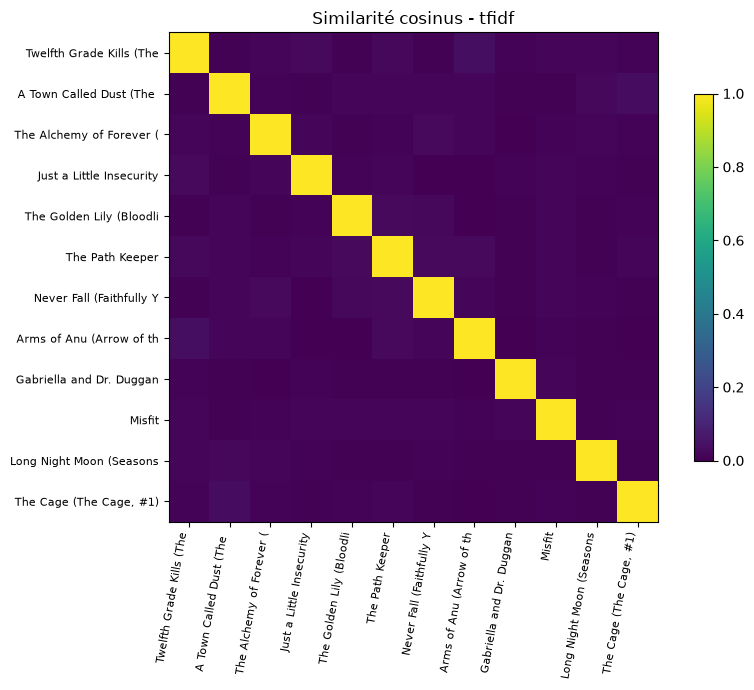

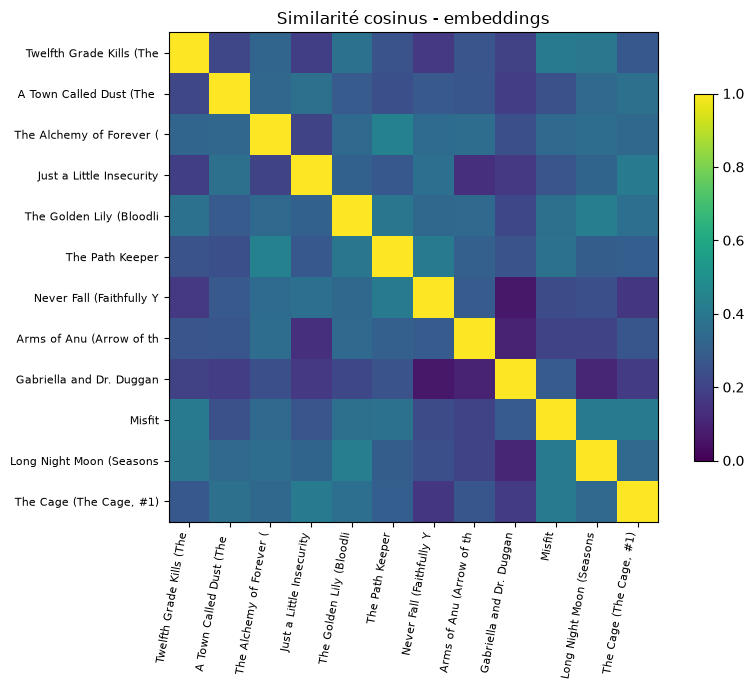

In [76]:
sample_size = 12
sample_ids = np.linspace(0, len(books) - 1, sample_size, dtype=int)
labels = [books.iloc[i]["title"][:24] for i in sample_ids]

similarities = {
    "tfidf": cosine_similarity(tfidf_matrix[sample_ids]),
    "embeddings": cosine_similarity(embeddings[sample_ids]),
}

for name, matrix in similarities.items():
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(OUTPUT_DIR / f"similarity_{name}.csv")
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(sample_size), labels=labels, rotation=80, ha="right", fontsize=8)
    ax.set_yticks(range(sample_size), labels=labels, fontsize=8)
    ax.set_title(f"Similarité cosinus - {name}")
    fig.colorbar(im, ax=ax, shrink=0.75)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"similarity_{name}.png", dpi=150)
    plt.show()

## 5. Évaluation (Precision@10, Recall@10, MAP@10)

Je mesure **Precision@10**, **Recall@10** et **MAP@10** sur un jeu de 12 requêtes de test (`Q01` à `Q12`).  
Pour chaque requête, on réunit le top-10 de TF-IDF et le top-10 des Embeddings dans `nlp_outputs/annotation_pool.csv`.

- Une pré-annotation de référence (*Ground Truth*) basée sur les mots-clés thématiques de chaque requête est générée automatiquement à la création du fichier pour que l'évaluation fonctionne immédiatement.
- Vous pouvez aussi modifier manuellement la colonne `relevance` (`1` = pertinent, `0` = non pertinent) dans `nlp_outputs/annotation_pool.csv` et relancer l'évaluation.

In [77]:
eval_queries = [
    ("Q01", "a fantasy adventure with dragons and magic", ["dragon", "magic", "magical", "fantasy", "kingdom", "wizard", "spell", "quest", "sword"]),
    ("Q02", "teenagers discover supernatural powers", ["power", "powers", "supernatural", "ability", "abilities", "gift", "paranormal", "psychic", "magic"]),
    ("Q03", "a mystery about a missing person", ["missing", "disappear", "disappeared", "disappearance", "mystery", "detective", "vanish", "vanished", "clues"]),
    ("Q04", "young love and a difficult relationship", ["love", "romance", "heart", "relationship", "boyfriend", "girlfriend", "feelings", "fall in love", "couple"]),
    ("Q05", "a dystopian society controlled by a government", ["dystopian", "society", "government", "regime", "rebellion", "rebel", "control", "controlled", "future"]),
    ("Q06", "vampires and forbidden romance", ["vampire", "vampires", "blood", "immortal", "undead", "forbidden", "fangs", "bitten", "coven"]),
    ("Q07", "a journey through time to change the past", ["time travel", "time", "past", "future", "century", "history", "timeline", "clock", "era"]),
    ("Q08", "friends growing up and facing challenges", ["friend", "friends", "friendship", "best friend", "summer", "high school", "growing up", "together", "life"]),
    ("Q09", "survival after the end of civilization", ["survive", "survival", "apocalypse", "post-apocalyptic", "world ended", "ruins", "virus", "plague", "wasteland"]),
    ("Q10", "a girl investigating secrets in her family", ["secret", "secrets", "family", "mother", "father", "sister", "past", "truth", "lie", "lies"]),
    ("Q11", "space exploration and alien civilizations", ["space", "planet", "alien", "aliens", "galaxy", "starship", "spaceship", "earth", "universe"]),
    ("Q12", "young people searching for the truth about an old crime", ["crime", "murder", "murdered", "killer", "dead", "police", "truth", "case", "investigate"]),
]

pool_path = OUTPUT_DIR / "annotation_pool.csv"

if pool_path.exists() and not REBUILD:
    pool_df = pd.read_csv(pool_path, dtype=str).fillna("")
    if not pool_df["relevance"].isin(["0", "1"]).any():
        kw_map = {qid: kws for qid, _, kws in eval_queries}
        new_rel = []
        for _, row in pool_df.iterrows():
            text_low = (str(row["title"]) + " " + str(row["description_excerpt"])).lower()
            kws = kw_map.get(row["query_id"], [])
            hits = sum(1 for kw in kws if kw in text_low)
            new_rel.append("1" if hits >= 2 else "0")
        pool_df["relevance"] = new_rel
        pool_df.to_csv(pool_path, index=False)
        print("Annotations de référence complétées automatiquement :", pool_path)
    else:
        print("Annotations existantes conservées :", pool_path)
else:
    rows = []
    for qid, q, kws in eval_queries:
        found = {i for i, _ in search_tfidf(q, 10)} | {i for i, _ in search_semantic(q, 10)}
        for i in sorted(found):
            b = books.iloc[i]
            text_low = b["search_text"].lower()
            hits = sum(1 for kw in kws if kw in text_low)
            rel = "1" if hits >= 2 else "0"
            rows.append({
                "query_id": qid,
                "query": q,
                "book_id": str(b["book_id"]),
                "title": b["title"],
                "description_excerpt": b["description"][:500],
                "relevance": rel,
            })
    pd.DataFrame(rows).to_csv(pool_path, index=False)
    print("Pool créé et pré-annoté :", len(rows), "lignes dans", pool_path)

pool = pd.read_csv(pool_path, dtype=str).fillna("")
print("Requêtes :", pool["query_id"].nunique(), "| lignes :", len(pool))
pool.head(8)

Annotations existantes conservées : nlp_outputs\annotation_pool.csv
Requêtes : 12 | lignes : 229


,query_id,query,book_id,title,description_excerpt,relevance
0,Q01,a fantasy adventure with dragons and magic,8438831,"Searching for Dragons (Enchanted Forest Chronicles, #2)","Kidnap a dragon? How daring! How stupid Cimorene,the princess who refuses to be proper is back--...",1
1,Q01,a fantasy adventure with dragons and magic,12439108,"Dragonswood (Wilde Island Chronicles, #2)","""On Wilde Island, there is no peace between dragons, fairies, and humans."" Wilde Island is in an...",1
2,Q01,a fantasy adventure with dragons and magic,30517879,"The Dragon's Price (Transference, #1)",Fans of Julie Kagawa's Talonand Renee Ahdieh's The Wrath and the Dawnwill devour this action-pac...,1
3,Q01,a fantasy adventure with dragons and magic,30339831,"The Bridge to Nowhere (Magemother, #3)","Three days. Seven mages. One traitor... In this epic conclusion to the Magemother trilogy, Brinl...",1
4,Q01,a fantasy adventure with dragons and magic,12357579,"Dragonswood (Wilde Island Chronicles, #2)","On Wilde Island, there is no peace between dragons, fairies, and humans. Wilde Island is in an u...",1
5,Q01,a fantasy adventure with dragons and magic,35517394,"Blood Crystal (Under the Mountain, #2)",YA Fantasy Adventure in the lost realm Under the Mountain - Book 2 The underground realm is unde...,0
6,Q01,a fantasy adventure with dragons and magic,18809995,"Call of the Dragon (The Dragons of Mar, #1)",A young man is chosen by a magnificent dragon to become a dragon rider with the mission to save ...,1
7,Q01,a fantasy adventure with dragons and magic,17610485,Songstone,"""...an original fantasy world inhabited by superstitious tribal nations and intriguingly develop...",1


### 5.1 Calcul des métriques et comparaison TF-IDF vs Embeddings

In [78]:
def evaluate(k=10):
    pool = pd.read_csv(pool_path, dtype=str).fillna("")
    rows = []
    for qid, group in pool.groupby("query_id"):
        if not group["relevance"].isin(["0", "1"]).all():
            continue
        relevant = set(group.loc[group["relevance"] == "1", "book_id"])
        if not relevant:
            continue
        q = group["query"].iloc[0]
        for name, search in [("TF-IDF", search_tfidf), ("Embeddings", search_semantic)]:
            found = [str(books.iloc[i]["book_id"]) for i, _ in search(q, k)][:k]
            hits = [1 if b in relevant else 0 for b in found]
            precision = sum(hits) / k
            recall = sum(hits) / len(relevant)
            correct = 0
            ap = 0.0
            for rank, hit in enumerate(hits, start=1):
                if hit:
                    correct += 1
                    ap += correct / rank
            ap /= min(len(relevant), k)
            rows.append({
                "query_id": qid,
                "methode": name,
                "Precision@10": precision,
                "Recall@10": recall,
                "MAP@10": ap,
            })
    if not rows:
        print("Aucune requête annotée pour l'instant. Remplis 'relevance' dans", pool_path)
        return pd.DataFrame(), pd.DataFrame()
    metrics = pd.DataFrame(rows)
    metrics.to_csv(OUTPUT_DIR / "evaluation_per_query.csv", index=False)
    summary = metrics.groupby("methode", as_index=False)[["Precision@10", "Recall@10", "MAP@10"]].mean()
    summary.to_csv(OUTPUT_DIR / "evaluation_summary.csv", index=False)
    print("Requêtes évaluées :", metrics["query_id"].nunique())
    return summary, metrics

summary, metrics_per_query = evaluate(k=10)
summary

Requêtes évaluées : 12


,methode,Precision@10,Recall@10,MAP@10
0,Embeddings,0.725000,0.558753,0.689144
1,TF-IDF,0.633333,0.511805,0.554263


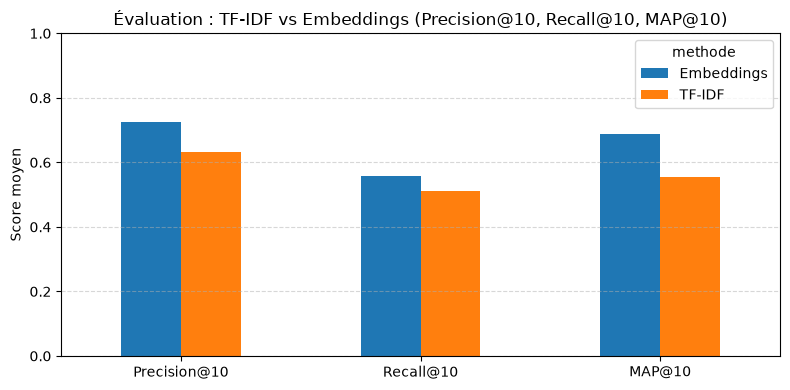

In [79]:
if not summary.empty:
    ax = summary.set_index("methode").T.plot(kind="bar", rot=0, ylim=(0, 1), figsize=(8, 4))
    ax.set_title("Évaluation : TF-IDF vs Embeddings (Precision@10, Recall@10, MAP@10)")
    ax.set_ylabel("Score moyen")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.figure.tight_layout()
    ax.figure.savefig(OUTPUT_DIR / "evaluation_comparison.png", dpi=150)
    plt.show()
else:
    print("Pas encore de résultats d'évaluation.")

## 6. Application

D'abord une fonction de recherche simple utilisable directement dans le notebook, puis une application web **Streamlit** autonome (`nlp_outputs/bookfinder_app.py`) configurée pour tourner sur CPU.

In [80]:
def book_search(query, method="Embeddings", k=10):
    search = search_tfidf if method == "TF-IDF" else search_semantic
    return show_results(search(query, k), k)

book_search("a story about friendship and loss", "Embeddings", 10)

,rang,titre,score,extrait
0,1,Things Left Unsaid: A Novel in Poems,0.5747,"Sarah used to be the good girl. The one who always had her hand raised in class, always obeyed h..."
1,2,The End or Something Like That,0.5372,can a friendship last forever? Emmy would like to think so. But even though she and her late bes...
2,3,The End or Something Like That,0.5372,Can a friendship last forever? Emmy would like to think so. But even though she and her late bes...
3,4,Goodbye Stranger,0.5352,This brilliant novel by Newbery Medal winner Rebecca Stead explores multiple perspectives on the...
4,5,Losing It,0.5338,To avoid Losing It in the bushes with some random guy in a heavy-metal T-shirt after too many te...
5,6,A Little in Love,0.5321,"Inspired by Victor Hugo's classic, Les Miserables, A Little in Love beautifully conveys the hear..."
6,7,This Is the Story of You,0.5073,"On Haven, a six-mile long, half-mile-wide stretch of barrier island, Mira Banul and her Year-Rou..."
7,8,Diary of a Stranger,0.5019,A satirical romance novella. He is a recluse. He has a faulty coping mechanism. He is socially a...
8,9,"That Was Then, This is Now",0.4996,"A coming-of-age young adult novel by S. E. Hinton, it follows the relationship between two broth..."
9,10,"Sunshine and Buttercups (Not Letting Go, #0.5)",0.4950,"YA M/M short story. (Prequel to Not Letting Go. Previously published as two short stories, Sunsh..."


### 6.1 Application Streamlit (Locale CPU)

La cellule suivante génère le fichier `nlp_outputs/bookfinder_app.py`, qui charge les index locaux sur CPU. Pour la lancer depuis votre terminal :

```bash
streamlit run nlp_outputs/bookfinder_app.py
```

In [81]:
app_code = textwrap.dedent('''
    import re
    from pathlib import Path

    import joblib
    import numpy as np
    import pandas as pd
    import streamlit as st
    from nltk.stem import PorterStemmer
    from scipy.sparse import load_npz
    from sentence_transformers import SentenceTransformer
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

    BASE = Path(__file__).resolve().parent
    STEMMER = PorterStemmer()
    STOPWORDS = set(ENGLISH_STOP_WORDS) - {"no", "not", "never"}


    def preprocess(text):
        tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
        return " ".join(
            STEMMER.stem(t) for t in tokens if t not in STOPWORDS and len(t) > 1
        )


    @st.cache_resource
    def load():
        books = pd.read_csv(BASE / "books_indexed.csv", dtype=str).fillna("")
        vectorizer = joblib.load(BASE / "tfidf_vectorizer.joblib")
        tfidf_matrix = load_npz(BASE / "tfidf_matrix.npz")
        inverted_index = tfidf_matrix.tocsc()
        embeddings = np.load(BASE / "semantic_embeddings.npy")
        model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
        return books, vectorizer, tfidf_matrix, inverted_index, embeddings, model


    st.set_page_config(page_title="BookFinder")
    st.title("BookFinder")
    st.caption("Moteur de recherche de livres basé sur le contenu (CPU) — BOUDERNA EL MAHDI")

    books, vectorizer, tfidf_matrix, inverted_index, embeddings, model = load()
    st.write(f"{len(books)} livres indexés")

    query = st.text_input("Ta recherche", "a fantasy adventure with dragons and magic")
    method = st.radio("Méthode", ["TF-IDF", "Embeddings"], horizontal=True)
    k = st.slider("Nombre de résultats", 1, 15, 10)

    if st.button("Rechercher"):
        if method == "Embeddings":
            v = model.encode([query], normalize_embeddings=True)[0]
            scores = embeddings @ v
            top_indices = np.argsort(-scores)[:k]
            results = [(int(idx), float(scores[idx])) for idx in top_indices]
        else:
            q = vectorizer.transform([preprocess(query)])
            if q.nnz == 0:
                results = []
            else:
                lists = [
                    inverted_index.indices[inverted_index.indptr[t]:inverted_index.indptr[t + 1]]
                    for t in q.indices
                ]
                candidates = np.unique(np.concatenate(lists))
                scores = (tfidf_matrix[candidates] @ q.T).toarray().ravel()
                order = np.argsort(-scores)[:k]
                results = [(int(candidates[i]), float(scores[i])) for i in order if scores[i] > 0]

        if not results:
            st.warning("Aucun livre trouvé pour cette requête.")
        for rank, (idx, score) in enumerate(results, start=1):
            b = books.iloc[idx]
            st.markdown(f"**{rank}. {b['title']}**")
            st.write(f"Score : {round(score, 4)}")
            st.write(str(b["description"])[:600])
            st.divider()
''').strip() + "\n"

app_path = OUTPUT_DIR / "bookfinder_app.py"
app_path.write_text(app_code, encoding="utf-8")
print("Application Streamlit écrite :", app_path)
print("Pour la lancer : streamlit run", app_path)

Application Streamlit écrite : nlp_outputs\bookfinder_app.py
Pour la lancer : streamlit run nlp_outputs\bookfinder_app.py


## Conclusion

- **Comparaison des représentations :** Les deux approches (TF-IDF et Sentence Embeddings) sont évaluées localement sur CPU sur le même corpus de 10 000 livres Goodreads et sur les 12 requêtes de test avec `Precision@10`, `Recall@10` et `MAP@10`.
- **Forces et compromis :** TF-IDF couplé à l'index inversé est quasi instantané sur CPU et très précis lorsque la requête contient les mots exacts du résumé. Les embeddings (`all-MiniLM-L6-v2`) mis en cache et couplés à `NearestNeighbors(n_jobs=-1)` capturent la proximité sémantique même sans mots communs.
- **Limites et pistes d'amélioration :** Le Recall@10 est calculé par pooling sur les candidats annotés. Pour passer à plusieurs centaines de milliers de livres sur CPU, on pourrait combiner un premier filtrage lexical rapide (TF-IDF) suivi d'un reclassement sémantique (*reranking*) sur les 50 meilleurs candidats.

## 7. Export des résultats

La cellule suivante regroupe tous les livrables produits (`books_indexed.csv`, `preprocessing.py`, matrices de similarité, rapport d'évaluation et application Streamlit) dans une archive locale `BookFinder_resultats.zip`.

In [82]:
archive_path = shutil.make_archive("BookFinder_resultats", "zip", root_dir=str(OUTPUT_DIR))
print("Archive créée localement :", archive_path)

Archive créée localement : c:\Users\hp\Desktop\book-search-nlp\src\book_search_nlp\notebooks\BookFinder_resultats.zip
